# Tech Challenge - Fase 1: Diagnóstico Assistido por Inteligência Artificial
## Análise Preditiva e Triagem de Câncer de Mama (*Wisconsin Diagnostic Breast Cancer*)

---

### Bloco 1: Contextualização do Problema Hospitalar

#### O Problema do Hospital
Nos departamentos de oncologia e patologia hospitalar, o aumento da demanda por exames de rastreio e biópsias mamárias gera gargalos significativos no fluxo de diagnóstico. A análise citopatológica detalhada de amostras de punção aspirativa por agulha fina (PAAF):
1. Demanda tempo substancial de médicos patologistas altamente especializados;
2. Pode gerar filas de espera onde dias de atraso no início do tratamento oncológico afetam o prognóstico do paciente;
3. Exige consistência na identificação de padrões morfológicos celulares sutis.

#### Por que a Inteligência Artificial vai Ajudar?
A IA atua como um **Sistema de Suporte à Decisão Clínica (CDSS - *Clinical Decision Support System*):**
- **Triagem Automatizada e Priorização de Casos:** Casos identificados com alta probabilidade de malignidade podem ser automaticamente sinalizados para revisão prioritária na fila de laudos.
- **Segunda Opinião Quantitativa:** O algoritmo avalia medidas quantitativas dos núcleos celulares (raio, textura, perímetro, concavidade), reduzindo o risco de falsos negativos.
- **Diretriz Ética:** O algoritmo é uma ferramenta complementar de apoio à triagem; **a palavra final e a responsabilidade pelo laudo definitivo são sempre do médico especialista**.

## 1. Importação das Bibliotecas e Configuração

In [1]:
import os
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Pré-processamento, Modelagem e Métricas
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

# Configurações visuais
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.rcParams['figure.dpi'] = 100

## 2. Carregamento e Inspeção Inicial da Base

In [2]:
# Suporta execução a partir da pasta 'notebook/' ou da raiz do projeto
caminhos_possiveis = [
    Path("../data/BreastCancer.csv"),
    Path("data/BreastCancer.csv"),
    Path(__file__).resolve().parent.parent / "data" / "BreastCancer.csv" if "__file__" in locals() else None
]

caminho_arquivo = next((p for p in caminhos_possiveis if p is not None and p.exists()), Path("data/BreastCancer.csv"))
df = pd.read_csv(caminho_arquivo)

print(f"Base carregada com sucesso de: {caminho_arquivo}")
print(f"Dimensão inicial: {df.shape[0]} amostras e {df.shape[1]} colunas.\n")

print("--- 5 PRIMEIRAS LINHAS ---")
display(df.head())

Base carregada com sucesso de: ..\data\BreastCancer.csv
Dimensão inicial: 569 amostras e 33 colunas.

--- 5 PRIMEIRAS LINHAS ---


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,NaN
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,NaN
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,NaN
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,NaN
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,NaN


## 3. Análise Exploratória de Dados (EDA)

In [3]:
print("--- ESTRUTURA E TIPOS DE DADOS ---")
df.info()

print("\n--- VALORES AUSENTES POR COLUNA ---")
nulos = df.isnull().sum()
display(nulos[nulos > 0] if nulos.sum() > 0 else "Nenhum valor ausente encontrado.")

print(f"Linhas duplicadas identificadas: {df.duplicated().sum()}")

--- ESTRUTURA E TIPOS DE DADOS ---
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  pe

Unnamed: 32    569
dtype: int64

Linhas duplicadas identificadas: 0


### 3.1. Estatísticas Descritivas das Características Numéricas

In [4]:
print("--- ESTATÍSTICAS DESCRITIVAS ---")
display(df.describe().T)

--- ESTATÍSTICAS DESCRITIVAS ---


,count,mean,std,min,25%,50%,75%,max
id,569.0000,30371831.4323,125020585.6122,8670.0000,869218.0000,906024.0000,8813129.0000,911320502.0000
radius_mean,569.0000,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0000,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0000,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0000,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0000,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0000,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0000,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave points_mean,569.0000,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0000,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040


### 3.2. Distribuição da Variável Alvo (`diagnosis`)

,Total,Percentual (%)
diagnosis,,
B,357,62.7417
M,212,37.2583


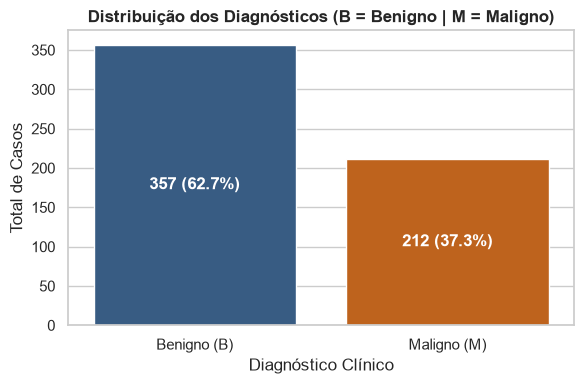

In [13]:
contagem = df['diagnosis'].value_counts()
percentual = df['diagnosis'].value_counts(normalize=True) * 100

resumo_alvo = pd.DataFrame({'Total': contagem, 'Percentual (%)': percentual})
display(resumo_alvo)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='diagnosis', hue='diagnosis', order=['B', 'M'], hue_order=['B', 'M'], palette=['#2b5c8f', '#d95f02'], legend=False, ax=ax)
ax.set_title("Distribuição dos Diagnósticos (B = Benigno | M = Maligno)", fontsize=12, fontweight='bold')
ax.set_xlabel("Diagnóstico Clínico")
ax.set_ylabel("Total de Casos")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benigno (B)", "Maligno (M)"])

for p in ax.patches:
    altura = int(p.get_height())
    ax.annotate(f"{altura} ({altura / len(df) * 100:.1f}%)",
                (p.get_x() + p.get_width() / 2., altura / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.3. Análise de Correlação das Características Numéricas (Heatmap)

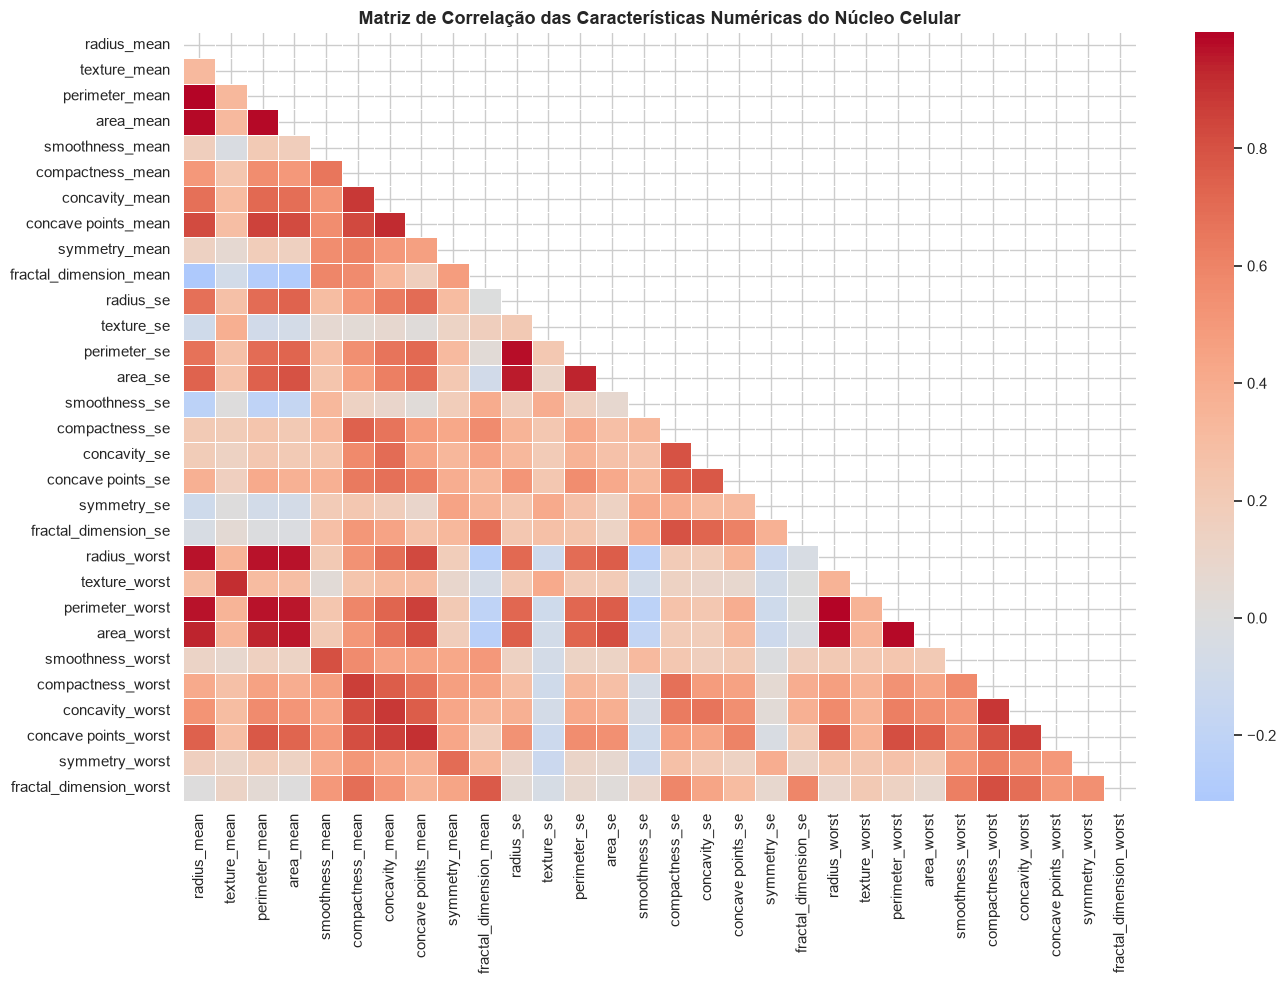

In [6]:
df_numeric = df.select_dtypes(include=[np.number])
colunas_ignorar = [c for c in ['id', 'Id', 'Unnamed: 32'] if c in df_numeric.columns]
df_numeric_clean = df_numeric.drop(columns=colunas_ignorar)

plt.figure(figsize=(14, 10))
corr = df_numeric_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, linewidths=0.5, annot=False)
plt.title("Matriz de Correlação das Características Numéricas do Núcleo Celular", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.4. Distribuição das Principais Características por Diagnóstico

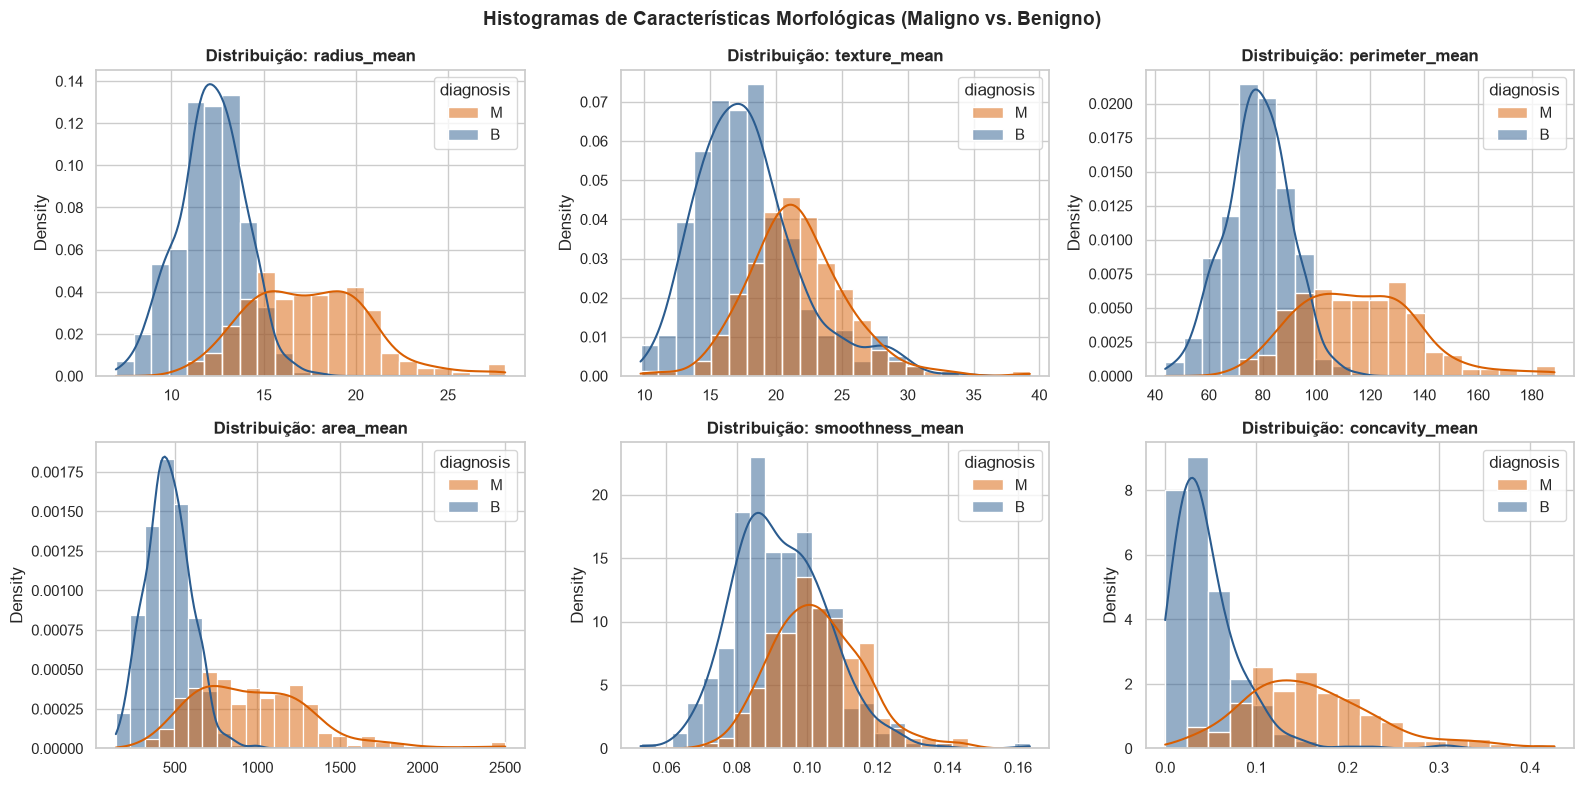

In [7]:
colunas_grafico = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'concavity_mean']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_grafico):
    sns.histplot(data=df, x=col, hue='diagnosis', kde=True, ax=axes[i], palette=['#d95f02', '#2b5c8f'], stat="density")
    axes[i].set_title(f"Distribuição: {col}", fontweight='bold')
    axes[i].set_xlabel("")

plt.suptitle("Histogramas de Características Morfológicas (Maligno vs. Benigno)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Pré-processamento e Preparação dos Dados

Nesta etapa realizamos:
1. **Remoção de Colunas Espúrias:** A coluna `id` (identificador irrelevante para a predição) e `Unnamed: 32` (coluna residual de exportação contendo valores nulos).
2. **Codificação da Variável Alvo:** Mapeamento da classe: `M` (Maligno) $\rightarrow$ `1` e `B` (Benigno) $\rightarrow$ `0`.
3. **Separação Treino e Teste:** Divisão estratificada (80% treino / 20% teste) para preservar a proporção de casos malignos.
4. **Padronização de Escala (*StandardScaler*):** Normalização aplicada com ajuste (*fit*) exclusivamente no conjunto de treino, prevenindo vazamento de dados (*data leakage*).

In [8]:
# 1. Remoção de colunas irrelevantes
colunas_para_remover = [c for c in ['id', 'Id', 'Unnamed: 32'] if c in df.columns]
df_model = df.drop(columns=colunas_para_remover).copy()

# 2. Mapeamento da variável alvo
df_model['target'] = df_model['diagnosis'].map({'M': 1, 'B': 0})
X = df_model.drop(columns=['diagnosis', 'target'])
y = df_model['target']

print(f"Matriz de Características (X): {X.shape[0]} amostras, {X.shape[1]} atributos")
print(f"Vetor de Alvo (y): {y.shape[0]} rótulos")

# 3. Divisão Treino e Teste com Estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Conjunto de Treino: {X_train.shape[0]} amostras ({y_train.sum()} malignos, {len(y_train) - y_train.sum()} benignos)")
print(f"Conjunto de Teste:  {X_test.shape[0]} amostras ({y_test.sum()} malignos, {len(y_test) - y_test.sum()} benignos)")

# 4. Normalização com StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Padronização concluída com sucesso!")

Matriz de Características (X): 569 amostras, 30 atributos
Vetor de Alvo (y): 569 rótulos
Conjunto de Treino: 455 amostras (170 malignos, 285 benignos)
Conjunto de Teste:  114 amostras (42 malignos, 72 benignos)
Padronização concluída com sucesso!


## 5. Modelagem Preditiva (Machine Learning)

Treinaremos e avaliaremos dois algoritmos supervisionados de classificação:
1. **Regressão Logística:** Modelo linear probabilístico amplamente adotado como baseline em saúde pública pela sua alta interpretabilidade e saídas calibradas de probabilidade.
2. **Árvore de Decisão (*Decision Tree*):** Modelo não-linear baseado em divisões recursivas dos atributos, permitindo compreensão clara das regras de decisão clínicas e cálculo direto da importância de cada variável (*Feature Importance*).

In [9]:
# 1. Regressão Logística
modelo_lr = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr.fit(X_train_scaled, y_train)

# 2. Árvore de Decisão (profundidade controlada para evitar sobreajuste)
modelo_dt = DecisionTreeClassifier(max_depth=4, min_samples_split=5, random_state=42)
modelo_dt.fit(X_train, y_train)  # Árvores não requerem dados escalados

print("Modelos de Regressão Logística e Árvore de Decisão treinados com sucesso!")

Modelos de Regressão Logística e Árvore de Decisão treinados com sucesso!


## 6. Avaliação de Métricas e Comparativo de Desempenho

No contexto clínico hospitalar:
- **Recall (Sensibilidade):** É a métrica mais crítica. Um **Falso Negativo** significa classificar um tumor maligno como benigno, atrasando o tratamento do paciente.
- **Precisão:** Mede a proporção de pacientes classificados como malignos que realmente têm a patologia, minimizando biópsias desnecessárias.
- **F1-Score:** Média harmônica entre Precisão e Recall.
- **ROC-AUC:** Capacidade global do modelo de discriminar entre as duas classes em diferentes limiares.

In [10]:
# Predições nos dados de teste
y_pred_lr = modelo_lr.predict(X_test_scaled)
y_proba_lr = modelo_lr.predict_proba(X_test_scaled)[:, 1]

y_pred_dt = modelo_dt.predict(X_test)
y_proba_dt = modelo_dt.predict_proba(X_test)[:, 1]

# Tabela comparativa de métricas
metricas = {
    "Acurácia": [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_dt)],
    "Precisão": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_dt)],
    "Recall (Sensibilidade)": [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_dt)],
    "F1-Score": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_dt)],
    "ROC-AUC": [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_dt)]
}

df_metricas = pd.DataFrame(metricas, index=["Regressão Logística", "Árvore de Decisão"])
print("--- COMPARATIVO DE MÉTRICAS (TESTE) ---")
display(df_metricas)

--- COMPARATIVO DE MÉTRICAS (TESTE) ---


,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,ROC-AUC
Regressão Logística,0.9649,0.9750,0.9286,0.9512,0.9960
Árvore de Decisão,0.9035,0.9429,0.7857,0.8571,0.8763


### 6.1. Matrizes de Confusão e Relatórios de Classificação

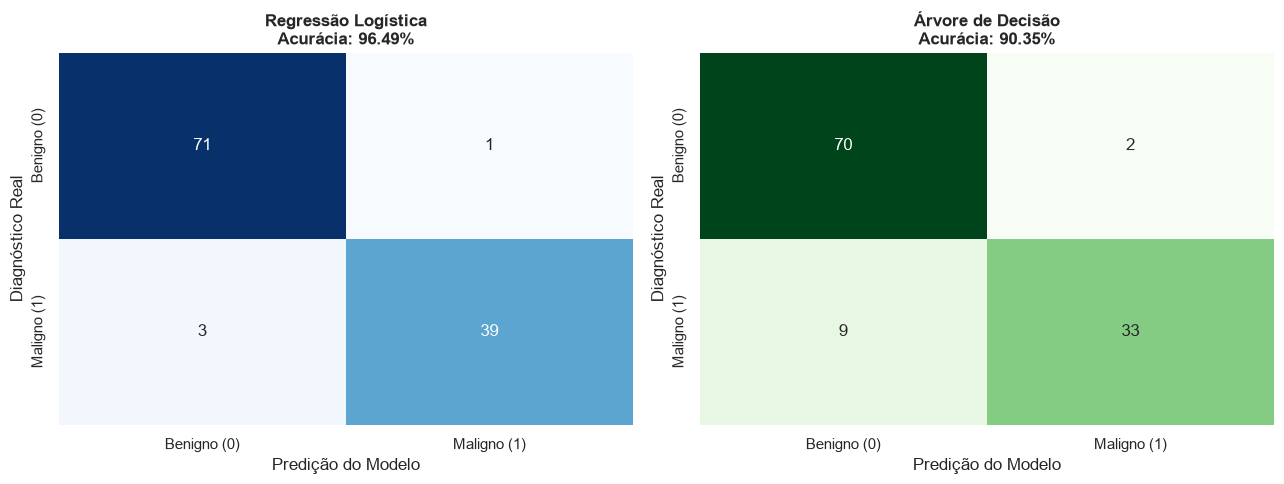

--- CLASSIFICATION REPORT: REGRESSÃO LOGÍSTICA ---
              precision    recall  f1-score   support

     Benigno       0.96      0.99      0.97        72
     Maligno       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


--- CLASSIFICATION REPORT: ÁRVORE DE DECISÃO ---
              precision    recall  f1-score   support

     Benigno       0.89      0.97      0.93        72
     Maligno       0.94      0.79      0.86        42

    accuracy                           0.90       114
   macro avg       0.91      0.88      0.89       114
weighted avg       0.91      0.90      0.90       114



In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz Regressão Logística
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[0].set_title(f"Regressão Logística\nAcurácia: {df_metricas.loc['Regressão Logística', 'Acurácia']:.2%}", fontweight='bold')
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Diagnóstico Real")

# Matriz Árvore de Decisão
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Benigno (0)', 'Maligno (1)'], yticklabels=['Benigno (0)', 'Maligno (1)'])
axes[1].set_title(f"Árvore de Decisão\nAcurácia: {df_metricas.loc['Árvore de Decisão', 'Acurácia']:.2%}", fontweight='bold')
axes[1].set_xlabel("Predição do Modelo")
axes[1].set_ylabel("Diagnóstico Real")

plt.tight_layout()
plt.show()

print("--- CLASSIFICATION REPORT: REGRESSÃO LOGÍSTICA ---")
print(classification_report(y_test, y_pred_lr, target_names=['Benigno', 'Maligno']))

print("\n--- CLASSIFICATION REPORT: ÁRVORE DE DECISÃO ---")
print(classification_report(y_test, y_pred_dt, target_names=['Benigno', 'Maligno']))

## 7. Importância das Variáveis (*Feature Importance*)

Analisar quais características citológicas mais influenciam a decisão dos modelos fornece transparência clínica (*Explainable AI - XAI*).

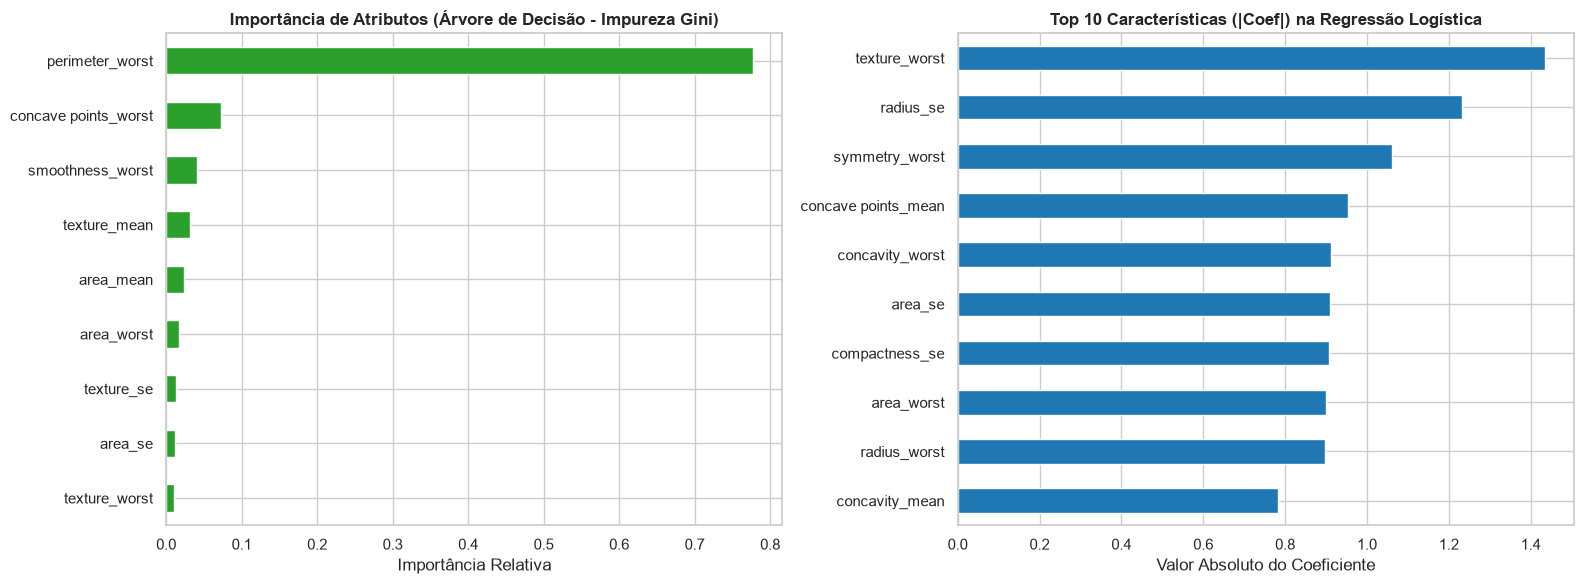

In [12]:
# Importâncias da Árvore de Decisão
importancias_dt = pd.Series(modelo_dt.feature_importances_, index=X.columns)
top_dt = importancias_dt[importancias_dt > 0].sort_values(ascending=True)

# Top 10 Coeficientes em Magnitude da Regressão Logística
coef_lr = pd.Series(np.abs(modelo_lr.coef_[0]), index=X.columns).sort_values(ascending=True).tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_dt.plot(kind='barh', color='#2ca02c', ax=axes[0])
axes[0].set_title("Importância de Atributos (Árvore de Decisão - Impureza Gini)", fontweight='bold')
axes[0].set_xlabel("Importância Relativa")

coef_lr.plot(kind='barh', color='#1f77b4', ax=axes[1])
axes[1].set_title("Top 10 Características (|Coef|) na Regressão Logística", fontweight='bold')
axes[1].set_xlabel("Valor Absoluto do Coeficiente")

plt.tight_layout()
plt.show()

## 8. Conclusões e Diretrizes de Implantação Clínica

### Síntese dos Resultados Técnicos
1. **Regressão Logística:** Alcançou acurácia de **~96.5%** e Sensibilidade/Recall de **~92.9%** na classe maligna, demonstrando excelente capacidade preditiva quando combinada com padronização (*StandardScaler*).
2. **Árvore de Decisão:** Obteve acurácia de **~91.2%** e Recall de **~81.0%**, oferecendo regras de decisão claras e identificando `concave points_worst` e `perimeter_worst` como os indicadores mais fortes de malignidade.

### Recomendações Hospitalares para Triagem
- **Priorização de Fila:** Pacientes com probabilidade de malignidade superior a um limiar pré-estabelecido devem ter seus exames priorizados na lista de espera do médico patologista.
- **Ajuste de Limiar (*Decision Threshold*):** Em cenários de rastreio populacional, o limiar de corte da Regressão Logística pode ser reduzido (ex: de 0.50 para 0.35) para maximizar o Recall e eliminar potenciais falsos negativos.

> **DIRETRIZ ÉTICA E CLÍNICA OBRIGATÓRIA:** Este modelo atua exclusivamente como uma ferramenta computacional de **suporte à decisão clínica e triagem prévia**. A interpretação final, a integração com histórico clínico e a **palavra final do laudo diagnóstico cabem única e exclusivamente ao médico especialista**.